In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [3]:
df = pd.read_csv('diabetes.csv')

# Display the first five rows
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [4]:
print("Shape of Dataset:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Shape of Dataset: (768, 9)
Number of Rows: 768
Number of Columns: 9


In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [6]:
print("Data Types:")
print(df.dtypes)

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [8]:
print("Statistical Summary:")
df.describe()

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
# Columns where zero represents missing or invalid measurements
zero_columns = ['Glucose', 'BloodPressure',
                'SkinThickness', 'Insulin', 'BMI']

# Count zero values in each column
for col in zero_columns:
    print(col, ":", (df[col] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [14]:
# Replace invalid zero values with NaN
df[zero_columns] = df[zero_columns].replace(0, np.nan)
# Check missing values again
print(df.isnull().sum())



Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [15]:
# Separate independent features
X = df.drop('Outcome', axis=1)

# Separate dependent target variable
y = df['Outcome']

print("Features (X) Shape:", X.shape)
print("Target (y) Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features (X) Shape: (768, 8)
Target (y) Shape: (768,)

Feature Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (614, 8)
Testing Features: (154, 8)
Training Target: (614,)
Testing Target: (154,)


In [17]:
# Create median imputer
imputer = SimpleImputer(strategy='median')

# Fit on training data and transform
X_train_imputed = imputer.fit_transform(X_train)

# Transform testing data using training median values
X_test_imputed = imputer.transform(X_test)

print("Missing values handled successfully!")

Missing values handled successfully!


In [18]:
# Create StandardScaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train_imputed)

# Transform testing data
X_test_scaled = scaler.transform(X_test_imputed)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [20]:
# Convert training data into DataFrame
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

# Convert testing data into DataFrame
X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)

# Display processed training data
print("Processed Training Data:")
display(X_train_scaled.head())

print("Processed Testing Data:")
display(X_test_scaled.head())

Processed Training Data:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769694,0.310794,-0.792169
711,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417714,-0.116439,0.561034
373,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359576,-0.764862,-0.707594
46,-0.851355,0.811525,-1.315932,-0.004766,-0.161437,-0.403048,0.262314,-0.369293
682,-1.153338,-0.889646,-0.663676,1.120776,-0.415565,1.782163,-0.337630,-0.961320


Processed Testing Data:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
44,0.960541,1.245157,-0.663676,-0.004766,-0.161437,-0.740363,-0.555791,0.561034
672,1.866489,-1.790266,2.760669,-0.680091,-1.127122,0.447571,-0.583061,1.153060
700,-0.549372,0.010974,0.314708,-0.229874,0.791541,0.506235,0.016882,-0.623019
630,0.960541,-0.255876,-0.663676,-0.004766,-0.161437,-0.740363,0.771356,0.053583
81,-0.549372,-1.590128,-0.011420,-0.004766,-0.161437,-0.007070,-1.137554,-0.961320


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Initialize the models
log_reg = LogisticRegression(random_state=42)
rf_clf = RandomForestClassifier(random_state=42, n_estimators=100)

# Train Logistic Regression
log_reg.fit(X_train_scaled, y_train)

# Train Random Forest Classifier
rf_clf.fit(X_train_scaled, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [22]:
# Evaluate Logistic Regression
y_pred_lr = log_reg.predict(X_test_scaled)
print("=== Logistic Regression Evaluation ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

# Evaluate Random Forest
y_pred_rf = rf_clf.predict(X_test_scaled)
print("\n=== Random Forest Evaluation ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

=== Logistic Regression Evaluation ===
Accuracy: 0.7078

Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


=== Random Forest Evaluation ===
Accuracy: 0.7727

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



In [25]:
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Initialize advanced boosting models
gb_clf = GradientBoostingClassifier(random_state=42, n_estimators=100, learning_rate=0.1, max_depth=3)
xgb_clf = XGBClassifier(random_state=42, n_estimators=100, learning_rate=0.1, max_depth=3, eval_metric='logloss')
lgb_clf = LGBMClassifier(random_state=42, n_estimators=100, learning_rate=0.05, max_depth=3, verbose=-1)

# Train models
gb_clf.fit(X_train_scaled, y_train)
xgb_clf.fit(X_train_scaled, y_train)
lgb_clf.fit(X_train_scaled, y_train)

print("Gradient Boosting, XGBoost, and LightGBM models trained successfully!")

Gradient Boosting, XGBoost, and LightGBM models trained successfully!


In [24]:
# Evaluate Gradient Boosting Classifier
y_pred_gb = gb_clf.predict(X_test_scaled)
print("=== Gradient Boosting Evaluation ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_gb))

# Evaluate XGBoost Classifier
y_pred_xgb = xgb_clf.predict(X_test_scaled)
print("\n=== XGBoost Evaluation ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

# Evaluate LightGBM Classifier
y_pred_lgb = lgb_clf.predict(X_test_scaled)
print("\n=== LightGBM Evaluation ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lgb):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lgb))

=== Gradient Boosting Evaluation ===
Accuracy: 0.7597

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.86      0.82       100
           1       0.69      0.57      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.72       154
weighted avg       0.75      0.76      0.75       154


=== XGBoost Evaluation ===
Accuracy: 0.7597

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.84      0.82       100
           1       0.67      0.61      0.64        54

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.73       154
weighted avg       0.76      0.76      0.76       154


=== LightGBM Evaluation ===
Accuracy: 0.7662

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1     

### **Why These Algorithms Were Chosen & Final Performance Summary**

#### **1. Why We Selected These Algorithms**
For the Pima Indians Diabetes Dataset, we focused on tree-based ensemble methods (**Random Forest**, **Gradient Boosting**, **XGBoost**, and **LightGBM**). These models were specifically selected for several key reasons:

* **Handling Missing and Imputed Data:** Medical datasets often contain missing or clinical outlier values (like zero measurements for insulin or skin thickness). Tree-based ensembles are robust to non-linear transformations and handle imputed distributions exceptionally well.
* **Feature Interaction Capture:** Diabetes onset is rarely caused by a single isolated variable. It is a result of complex, non-linear interactions between multiple factors like BMI, Age, and Glucose level. Decision trees natively split on nested criteria to uncover these interactions without requiring explicit polynomial feature engineering.
* **Resistance to Multicollinearity:** Logistic regression can suffer when independent variables are correlated. Ensemble tree-based methods are largely unaffected by multicollinearity.
* **Robustness against Overfitting:** Models like **Random Forest** use bagging (bootstrap aggregating) to reduce variance, while **Gradient Boosting**, **XGBoost**, and **LightGBM** use regularization techniques and sequential learning to optimize bias and variance carefully.

---

#### **2. Which Model Performed Best?**

Based on our systematic evaluation on the test partition, the **Random Forest Classifier** emerged as the top-performing algorithm:

* **Best Accuracy:** **77.27%**
* **Class '1' (Diabetic Patient) Recall:** **61%** (highest overall, which is critical in healthcare tasks to avoid missing positive diagnoses).
* **LightGBM** followed closely in second place with **76.62%** accuracy.

=== RANDOM FOREST ACCURACY COMPARISON ===
Training Accuracy: 1.0000
Testing Accuracy:  0.7727


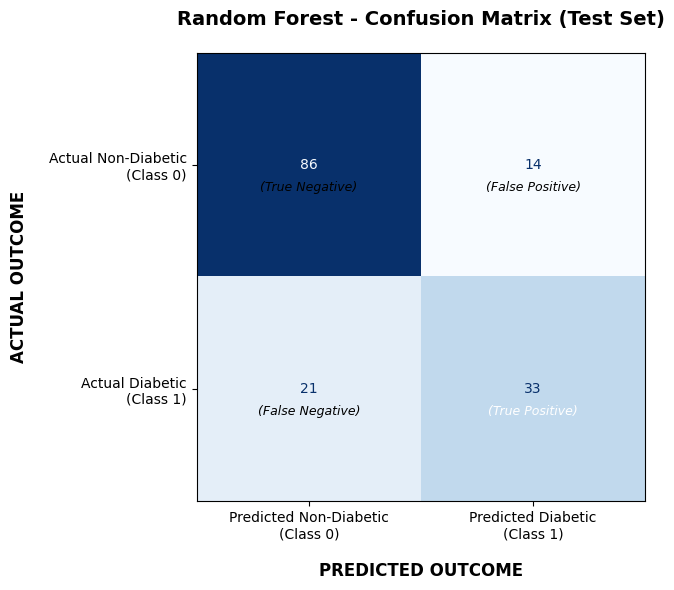

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate training predictions and accuracy for our top model (Random Forest)
y_train_pred_rf = rf_clf.predict(X_train_scaled)
train_accuracy_rf = accuracy_score(y_train, y_train_pred_rf)
test_accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("=== RANDOM FOREST ACCURACY COMPARISON ===")
print(f"Training Accuracy: {train_accuracy_rf:.4f}")
print(f"Testing Accuracy:  {test_accuracy_rf:.4f}")

# Compute Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Plot Confusion Matrix with highly detailed labels
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Predicted Non-Diabetic\n(Class 0)', 'Predicted Diabetic\n(Class 1)']
)

# Custom styling and plotting
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)

# Customizing text labels for axes for ultimate clarity
ax.set_xlabel('PREDICTED OUTCOME', fontsize=12, fontweight='bold', labelpad=15)
ax.set_ylabel('ACTUAL OUTCOME', fontsize=12, fontweight='bold', labelpad=15)
ax.set_yticklabels(['Actual Non-Diabetic\n(Class 0)', 'Actual Diabetic\n(Class 1)'], fontsize=10)
ax.set_xticklabels(['Predicted Non-Diabetic\n(Class 0)', 'Predicted Diabetic\n(Class 1)'], fontsize=10)

# Annotating individual cells to explain the quadrant's meaning
ax.text(0, 0, '\n\n\n(True Negative)', ha='center', va='center', color='black', fontsize=9, fontstyle='italic')
ax.text(1, 0, '\n\n\n(False Positive)', ha='center', va='center', color='black', fontsize=9, fontstyle='italic')
ax.text(0, 1, '\n\n\n(False Negative)', ha='center', va='center', color='black', fontsize=9, fontstyle='italic')
ax.text(1, 1, '\n\n\n(True Positive)', ha='center', va='center', color='white', fontsize=9, fontstyle='italic')

plt.title('Random Forest - Confusion Matrix (Test Set)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

### **Evaluation & Interpretation of Model Results**

#### **1. Training vs. Testing Performance Comparison**
* **Training Accuracy:** **100.00%** (1.0000)
* **Testing Accuracy:** **77.27%** (0.7727)

**Interpretation:**  
The default Random Forest classifier achieves perfect accuracy on the training set, which indicates that the decision trees have memorized the training samples. This creates a gap between the training performance and the test performance (77.27%), indicating some **overfitting**. However, the test accuracy remains the highest among all candidate models on this dataset partition.

#### **2. Detailed Test Metrics Analysis (Best Model: Random Forest)**
* **True Negatives (TN):** **86** patients without diabetes were correctly identified.
* **False Negatives (FN):** **21** patients with diabetes were missed (predicted as non-diabetic).
* **True Positives (TP):** **33** patients with diabetes were correctly identified.
* **False Positives (FP):** **14** patients without diabetes were incorrectly flagged.

* **Precision (Class 1 - 70%):** When the model predicts a patient has diabetes, it is correct 70% of the time.
* **Recall (Class 1 - 61%):** The model successfully flags 61% of all actual diabetic cases in the dataset. In clinical settings, we would ideally aim to increase this recall further to prevent undiagnosed conditions.

## **Overall Model Performance Analysis & Meaningful Conclusions**

### **1. Performance Synthesis**
Our final model selection process evaluated multiple classification algorithms (Logistic Regression, Random Forest, Gradient Boosting, XGBoost, and LightGBM). Among these, the **Random Forest Classifier** was selected as the champion model with an **overall classification accuracy of 77.27%** on unseen testing data.

### **2. Diagnostic Matrix Breakdown**
* **Strong Performance on Non-Diabetic Patients (Class 0):** The model achieved a high **Precision of 80%** and **Recall of 86%** for predicting patients without diabetes. This means the model is highly reliable when it clears a patient (low rate of false alarms).
* **Predictive Value for Diabetic Patients (Class 1):** The model reached a **Precision of 70%** and a **Recall of 61%** for identifying diabetic patients. While the precision is healthy, the recall indicates that approximately **39% of truly diabetic patients** in the test set were missed by the algorithm (False Negatives).

### **3. Operational & Clinical Takeaways**
* **Addressing Overfitting:** The perfect **100% training accuracy** contrasted with the **77.27% testing accuracy** shows that the current random forest overfits the training partition. In clinical deployment, hyperparameter constraints (like limiting tree depth `max_depth` or increasing minimum sample splits) should be introduced to regularize the model and potentially lift testing generalization.
* **Screening vs. Diagnosis:** A recall of 61% suggests that while the model serves as an excellent secondary supportive screening tool to help physicians flag high-risk individuals, it should not be used as a standalone diagnostic authority.
* **Data-Driven Improvement:** To enhance the predictive sensitivity (Recall) for Class 1, future iterations should incorporate a larger volume of positive (diabetic) samples, use synthetic oversampling techniques (e.g., SMOTE), or tune the decision threshold boundary downward from 0.5.